# 2. Pronóstico de ozono en la CDMX con ARIMA

**Pregunta.** ¿Se puede anticipar con un día de ventaja el máximo de ozono de la red de monitoreo y el riesgo de llegar al nivel de contingencia (155 ppb)?

**Datos.** Concentraciones horarias de O₃ por estación de la red Valle de México (RAMA), 2015 en adelante, obtenidas por **web scraping** del formulario de consulta de SINAICA (INECC) con un navegador Chromium controlado por Playwright (`01_scraping_sinaica_navegador.ipynb`).

**Método.** Box-Jenkins con regresión armónica (estacionalidad anual) y día de la semana con errores ARIMA. Se elige el modelo en validación y se evalúa fuera de muestra contra tres referencias ingenuas.

| Sección | Qué responde |
|---|---|
| 1. Datos | De dónde salen, cuántos son, qué reglas de calidad se aplicaron |
| 2. ¿Cuándo y dónde? | Hora, mes, año y estación en que el ozono es peor |
| 3–4. Serie y estructura | Si la serie es estacionaria y qué estructura ARMA tiene |
| 5–6. Modelo | Selección en validación y diagnóstico de residuos |
| 7–9. Prueba | Precisión fuera de muestra, horizonte útil y alerta de contingencia |
| 10. Extensión horaria | SARIMA con estacionalidad de 24 h |
| 11–12. Uso y conclusiones | Pronóstico de la próxima semana, limitaciones y siguientes pasos |

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")      # avisos de convergencia/frecuencia de statsmodels; la validez se revisa abajo
pd.set_option("display.width", 140)
pd.set_option("display.precision", 2)

# ---- Parámetros: cámbialos si corres el scraper con datos más recientes ----
RUTA = Path("datos_scraping/salida")   # tablas del web scraping de SINAICA (01_scraping_sinaica_navegador.ipynb)
CATALOGO = Path("datos_scraping/catalogos/estaciones.csv")   # nombres del formulario de SINAICA + coordenadas
FIN_ENTRENAMIENTO = "2021-12-31"       # se estima con 2015-2021
VALIDACION = ("2022-01-01", "2023-12-31")   # se elige el modelo aquí (dos años: con uno solo el orden de los candidatos no era estable)
INICIO_PRUEBA = "2024-01-01"           # se evalúa aquí, sin volver a elegir nada
UMBRAL_FASE1 = 155                     # ppb en 1 h: activa la Fase I de contingencia (CAMe)
LIMITE_NOM = 90                        # ppb en 1 h: límite de la NOM-020-SSA1-2021 (0.090 ppm)
MIN_ESTACIONES = 10                    # días con menos estaciones válidas se tratan como faltantes

In [2]:
# ---- Estilo de gráficas: superficie clara, tinta neutra, paleta categórica validada (orden fijo) ----
SUP, TINTA, TINTA2, TENUE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
REJILLA, EJE = "#e1e0d9", "#c3c2b7"
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
AZUL_CLARO = "#9ec5f4"
CRITICO, SERIO = "#d03b3b", "#ec835a"          # colores de estado: solo para umbrales, siempre con etiqueta
RAMPA_AZUL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
mpl.rcParams.update({
    "figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP, "figure.dpi": 110,
    "axes.edgecolor": EJE, "axes.linewidth": 0.8, "axes.labelcolor": TINTA2,
    "axes.titlecolor": TINTA, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": EJE, "ytick.color": EJE, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "lines.linewidth": 1.4, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "legend.labelcolor": TINTA2, "font.size": 9.5,
    "axes.prop_cycle": mpl.cycler(color=[AZUL, NARANJA, AQUA, AMARILLO]),
    "figure.constrained_layout.use": True,
})
FIG, RES = Path("figuras"), Path("resultados")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)


def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")


def linea_umbral(ax, valor, color, texto):
    ax.axhline(valor, color=color, lw=0.9, zorder=1)
    ax.annotate(texto, xy=(1, valor), xycoords=("axes fraction", "data"), xytext=(-4, 3),
                textcoords="offset points", ha="right", va="bottom", color=TINTA2, fontsize=8.5,
                bbox=dict(boxstyle="round,pad=0.2", fc=SUP, ec="none", alpha=0.9), zorder=5)


def nombre_est(cve):
    return nombres.get(cve, cve).replace("Santa FE", "Santa Fe") + f" ({cve})"


def barras(ax, posiciones, valores, ancho, color=AZUL, horizontal=False):
    # Barras delgadas; el trazo redondeado da el extremo redondo y la línea base lo recorta en cuadrado
    kw = dict(color=color, edgecolor=color, linewidth=3.5, joinstyle="round", zorder=3)
    if horizontal:
        ax.barh(posiciones, valores, height=ancho, **kw)
        ax.set_xlim(left=0)
    else:
        ax.bar(posiciones, valores, width=ancho, **kw)
        ax.set_ylim(bottom=0)

## 1. Datos

`scraper_sinaica_navegador.py` llena el formulario de consulta de SINAICA con Chromium (una búsqueda por estación y mes) y `scraper_simat.py` pasa las respuestas a formato largo. `consolidar` aplica estas reglas antes de cualquier análisis:

| Regla | Por qué importa |
|---|---|
| `-99`, `nr` y vacío → faltante | Si se promedian como números hunden las medias |
| Hora 1-24 = promedio del intervalo (h-1, h]; la hora 24 es del mismo día | `pd.to_datetime("24:00")` falla o corre el dato al día siguiente |
| Validados y crudos de SINAICA: gana el validado; los crudos solo rellenan horas faltantes | Los meses recientes todavía no están validados |
| Negativos se eliminan; > 350 ppb se marcan | Errores de sensor |
| 6 h o más con el mismo valor se marcan como sensor "pegado" | Solo se marcan; no se borran a ciegas |
| Un día de estación es válido con 18 horas o más (75 %) | Criterio usual de suficiencia para indicadores diarios |
| Días con menos de 10 estaciones válidas → faltante | El máximo de la red depende de cuántas estaciones operan |

**En esta corrida** (noviembre de 2026) se hicieron 4,366 búsquedas en el formulario: 2.5 millones de filas estación-hora crudas y 2.1 millones válidas después de la limpieza, de 26 estaciones. Lo raspado coincide en el 99.1 % de 1.84 millones de horas con los archivos oficiales del SIMAT, que se usaron solo para validar y no entran al análisis. **Desde octubre de 2024 los datos son preliminares** (SINAICA aún no los valida): se les aplica un filtro extra de picos aislados y pueden cambiar cuando se validen.

In [3]:
diario = pd.read_csv(RUTA / "o3_diario_red.csv", parse_dates=["fecha"]).set_index("fecha").asfreq("D")
horario = pd.read_csv(RUTA / "o3_horario_red.csv", parse_dates=["fecha_hora"]).set_index("fecha_hora").asfreq("h")
nombres = (pd.read_csv(CATALOGO).set_index("cve_estac")["nom_estac"].to_dict() if CATALOGO.exists() else {})

y = diario["maximo_red"].where(diario["n_estaciones_validas"] >= MIN_ESTACIONES).astype(float)
print(f"Serie diaria: {y.index.min():%Y-%m-%d} a {y.index.max():%Y-%m-%d} | {len(y):,} días | "
      f"con dato: {y.notna().sum():,} | sin dato: {y.isna().sum():,}")
print(f"Tabla horaria de la red: {horario['maximo'].notna().sum():,} horas con dato")
calidad = RUTA / "calidad_o3.txt"
if calidad.exists():
    print("\n" + calidad.read_text(encoding="utf-8").split("\nEstaciones con menor")[0])

Serie diaria: 2015-01-01 a 2026-11-09 | 4,331 días | con dato: 4,309 | sin dato: 22
Tabla horaria de la red: 101,648 horas con dato

REPORTE DE CALIDAD - O3 (ppb)
Archivos: 3295 | valores leídos: 2,103,690 | fuentes: {'sinaica': 1954891, 'sinaica_prelim': 148799}
Horas fuera de 1..24 descartadas: 0
Cruce sinaica vs sinaica_prelim: 73 horas en común | idénticas 87.7% | dif. media 0.25 ppb
Duplicados resueltos (prioridad rama > opendata > sinaica > web > sinaica_prelim): 73
Negativos eliminados: 0
Fuera de rango plausible (> 350 ppb, excluidos de las tablas): 0
Sensor 'pegado' (>= 6 h idénticas, solo marcado): 143
Picos aislados en datos preliminares (excluidos de las tablas): 6
Valores preliminares (sin validar) en la tabla final: 148,726 | desde 2024-10-18

Periodo: 2015-01-01 a 2026-11-09 | estaciones: 26
Valores finales: 2,103,617 (tabla horaria por estación)
Horas de red: 101,648 | días: 4,318 | días con < 10 estaciones válidas: 9



## 2. ¿Cuándo y dónde es peor el ozono?

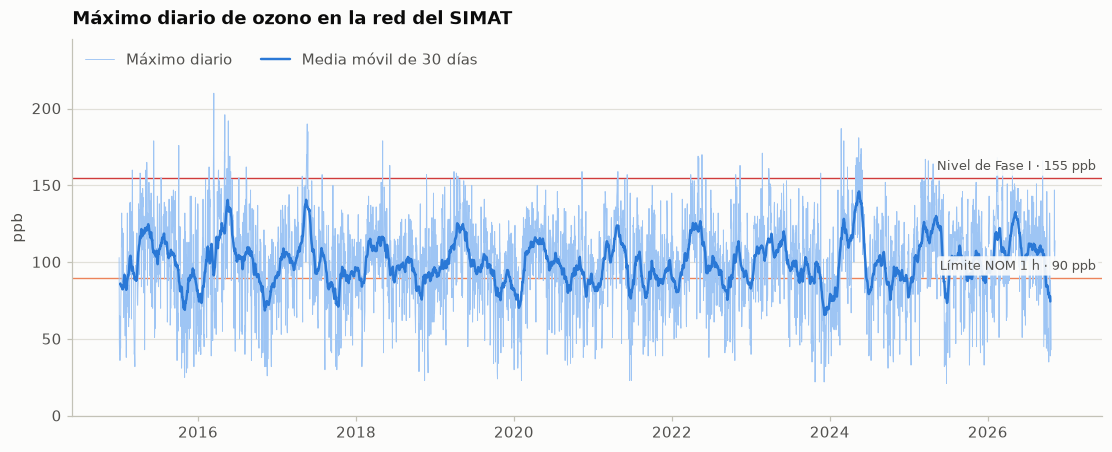

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.0))
ax.plot(y.index, y, color=AZUL_CLARO, lw=0.6, label="Máximo diario")
ax.plot(y.index, y.rolling(30, min_periods=20, center=True).mean(), color=AZUL, lw=1.6, label="Media móvil de 30 días")
linea_umbral(ax, UMBRAL_FASE1, CRITICO, f"Nivel de Fase I · {UMBRAL_FASE1} ppb")
linea_umbral(ax, LIMITE_NOM, SERIO, f"Límite NOM 1 h · {LIMITE_NOM} ppb")
ax.set_ylim(0, 245)
ax.set_ylabel("ppb")
ax.set_title("Máximo diario de ozono en la red del SIMAT")
ax.legend(loc="upper left", ncols=2)
guardar(fig, "01_serie_diaria")
plt.show()

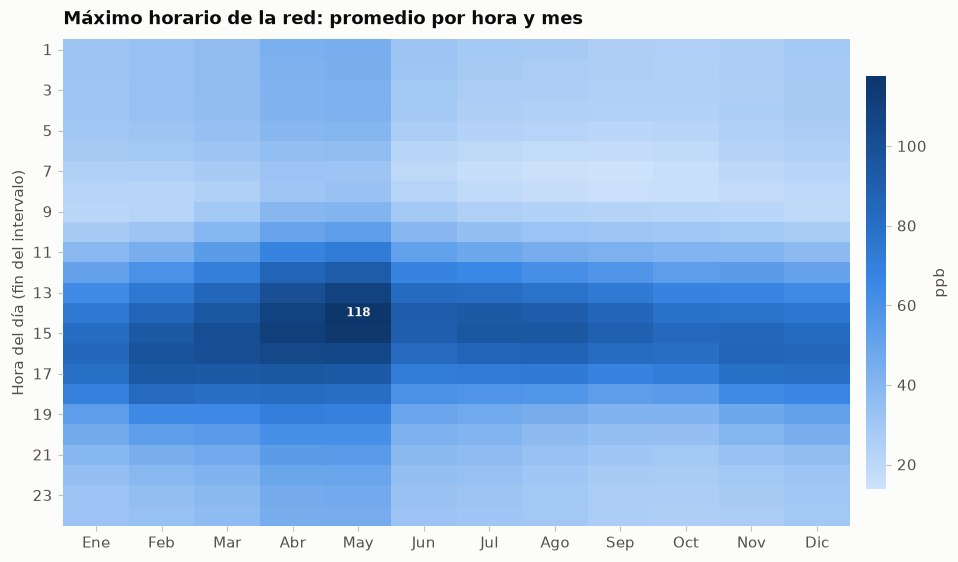

Pico típico: May a las 14:00 h, con 118 ppb en promedio


In [5]:
hm = (horario.assign(mes=horario.index.month, hora=horario.index.hour + 1)
      .pivot_table(index="hora", columns="mes", values="maximo", aggfunc="mean"))
fig, ax = plt.subplots(figsize=(8.6, 5.0))
im = ax.imshow(hm.to_numpy(), aspect="auto", cmap=RAMPA_AZUL, origin="upper")
meses_txt = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
ax.set_xticks(range(12), meses_txt)
ax.set_yticks(range(0, 24, 2), hm.index[::2])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
i, j = np.unravel_index(np.nanargmax(hm.to_numpy()), hm.shape)
ax.annotate(f"{hm.iat[i, j]:.0f}", (j, i), ha="center", va="center", color="#ffffff", fontsize=8, fontweight="bold")
cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cb.set_label("ppb", color=TINTA2)
cb.outline.set_visible(False)
cb.ax.tick_params(color=EJE, labelcolor=TINTA2)
ax.set_ylabel("Hora del día (fin del intervalo)")
ax.set_title("Máximo horario de la red: promedio por hora y mes")
guardar(fig, "02_hora_mes")
plt.show()
print(f"Pico típico: {meses_txt[j]} a las {hm.index[i]}:00 h, con {hm.iat[i, j]:.0f} ppb en promedio")

,dias_con_dato,dias_sobre_nom,dias_nivel_fase1,maximo_anual,pct_dias_sobre_nom
anio,,,,,
2015,365,229,8,179.0,62.7
2016,366,213,16,210.0,58.2
2017,365,245,10,190.0,67.1
2018,365,248,3,179.0,67.9
2019,365,235,3,159.0,64.4
2020,366,233,1,159.0,63.7
2021,365,215,2,159.0,58.9
2022,365,225,6,170.0,61.6
2023,365,238,4,171.0,65.2


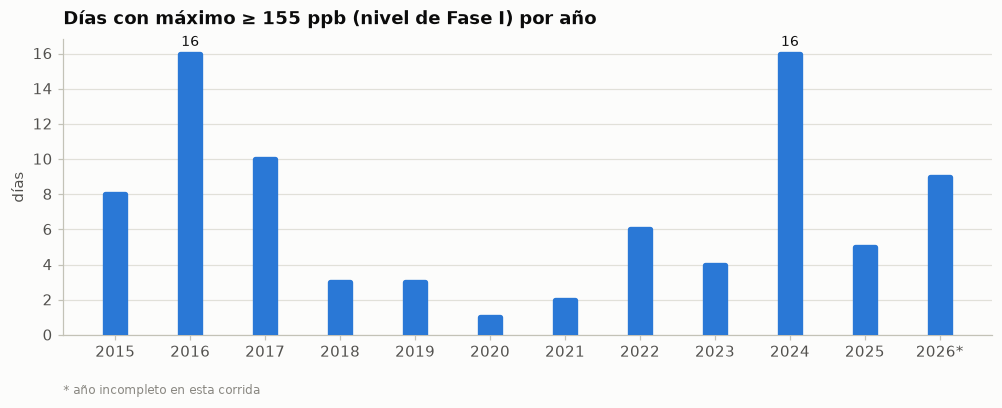

In [6]:
anual = (y.to_frame("maximo").assign(anio=y.index.year).groupby("anio")["maximo"]
         .agg(dias_con_dato="count",
              dias_sobre_nom=lambda s: int((s > LIMITE_NOM).sum()),
              dias_nivel_fase1=lambda s: int((s >= UMBRAL_FASE1).sum()),
              maximo_anual="max"))
anual["pct_dias_sobre_nom"] = (100 * anual["dias_sobre_nom"] / anual["dias_con_dato"]).round(1)
display(anual)

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(anual))
barras(ax, x, anual["dias_nivel_fase1"], 0.26)
etiquetas = [f"{a}*" if anual.loc[a, "dias_con_dato"] < 360 else str(a) for a in anual.index]
ax.set_xticks(x, etiquetas)
for a, v in anual["dias_nivel_fase1"].nlargest(2).items():
    ax.annotate(f"{v}", (list(anual.index).index(a), v), xytext=(0, 5), textcoords="offset points",
                ha="center", color=TINTA, fontsize=9)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylabel("días")
ax.set_title(f"Días con máximo ≥ {UMBRAL_FASE1} ppb (nivel de Fase I) por año")
ax.text(0, -0.2, "* año incompleto en esta corrida", transform=ax.transAxes, color=TENUE, fontsize=8)
guardar(fig, "03_dias_fase1_por_anio")
plt.show()

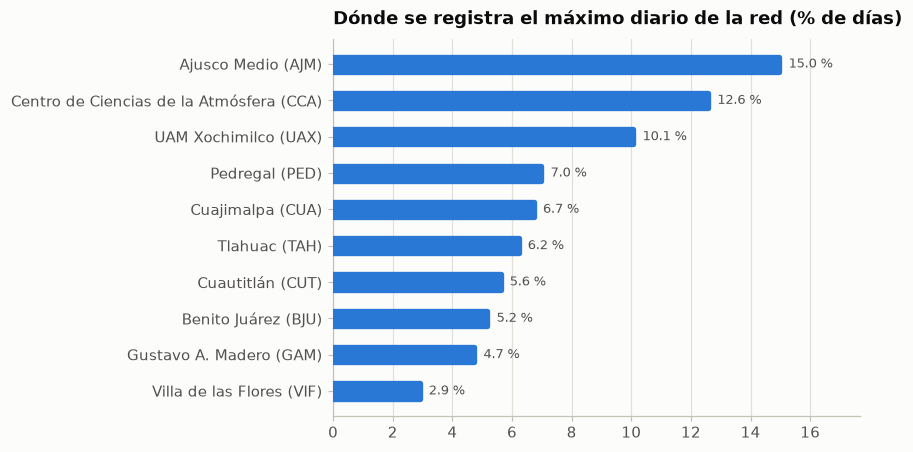

In [7]:
rank = diario.loc[y.notna(), "estacion_max"].value_counts(normalize=True).head(10).sort_values() * 100
fig, ax = plt.subplots(figsize=(7.8, 4.0))
pos = np.arange(len(rank))
barras(ax, pos, rank.to_numpy(), 0.42, horizontal=True)
ax.set_yticks(pos, [nombre_est(c) for c in rank.index])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
for k, v in enumerate(rank.to_numpy()):
    ax.annotate(f"{v:.1f} %", (v, k), xytext=(6, 0), textcoords="offset points", va="center", color=TINTA2, fontsize=8.5)
ax.set_xlim(0, rank.max() * 1.18)
ax.set_title("Dónde se registra el máximo diario de la red (% de días)")
guardar(fig, "04_estaciones_maximo")
plt.show()

**Lectura.**
- **Hora.** El ozono es un contaminante secundario: se forma con radiación solar a partir de NOx y COV. Por eso el pico cae a media tarde.
- **Temporada.** El pico ocurre en la temporada seca-caliente (marzo-mayo).
- **Lugar.** El máximo de la red aparece sobre todo en el sur y suroeste. Cinco estaciones del sur (Ajusco Medio, CCA-UNAM, UAM Xochimilco, Pedregal y Tláhuac) concentran el 51 % de los días; Ajusco Medio encabeza con 15 %. El viento arrastra la masa de aire contaminada hacia ese lado de la cuenca. El poniente (Cuajimalpa, 7 %) y el norte (Cuautitlán, 6 %; Gustavo A. Madero, 5 %) también aparecen. Milpa Alta y Ajusco, que en la red completa también destacan, no están disponibles en el formulario de SINAICA.
- **Gravedad.** El límite horario de la NOM se rebasa en la mayoría de los días del año. El nivel de Fase I es raro pero no excepcional: varía de 1 a 18 días por año.

## 3. Serie diaria y regresores

La serie a modelar es $y_t$, el máximo diario de O₃ de la red (ppb). La estacionalidad anual tiene periodo de 365.25 días. Un SARIMA con $s=365$ no es práctico: un rezago estacional de 365 días deja muy pocos ciclos para estimar y el espacio de estados es enorme. La práctica estándar es modelarla con términos de Fourier como regresores (regresión armónica dinámica):

$$y_t = \beta_0 + \sum_{k=1}^{K}\Big[a_k \sin\tfrac{2\pi k t}{365.25} + b_k \cos\tfrac{2\pi k t}{365.25}\Big] + \sum_{j=1}^{6}\gamma_j D_{j,t} + \eta_t, \qquad \eta_t \sim \text{ARIMA}(p,d,q)$$

donde $D_{j,t}$ son indicadoras de día de la semana (lunes = referencia).

In [8]:
ORIGEN = pd.Timestamp("2000-01-01")    # origen fijo: la fase de los armónicos no depende del corte de datos


def regresores(idx, K, dia_semana=True):
    t = (idx - ORIGEN).days.to_numpy(float)
    cols = {"const": np.ones(len(idx))}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * t / 365.25)
        cols[f"cos{k}"] = np.cos(2 * np.pi * k * t / 365.25)
    if dia_semana:
        for j, d in enumerate(["mar", "mie", "jue", "vie", "sab", "dom"], start=1):
            cols[d] = (idx.dayofweek == j).astype(float)
    return pd.DataFrame(cols, index=idx)


def ajustar(y, X, orden, hasta, estacional=(0, 0, 0, 0)):
    mod = SARIMAX(y[:hasta], exog=None if X is None else X[:hasta], order=orden, seasonal_order=estacional)
    return mod.fit(disp=False, maxiter=200)


def un_paso(res, y, X, orden, estacional, inicio, fin):
    # Pronósticos a 1 día en [inicio, fin] con los parámetros fijos de `res`: el filtro de Kalman usa
    # solo información hasta t-1 y no se vuelve a estimar nada, así que no hay fuga de información.
    completo = SARIMAX(y, exog=X, order=orden, seasonal_order=estacional).filter(res.params)
    p = completo.get_prediction(start=inicio, end=fin)
    return p.predicted_mean, p.se_mean, completo


def climatologia(y, hasta, idx):
    # Referencia ingenua "lo normal para esta fecha": media histórica por día del año (mes-día) con datos hasta `hasta`.
    # Es más exigente que la parte armónica del propio modelo, así que la ventaja que se reporte contra ella no queda inflada.
    hist = y[:hasta].dropna()
    tabla = hist.groupby([hist.index.month, hist.index.day]).mean()
    if (2, 29) not in tabla.index or pd.isna(tabla.loc[(2, 29)]):
        tabla.loc[(2, 29)] = tabla.loc[(2, 28)]
    return pd.Series(tabla.reindex(pd.MultiIndex.from_arrays([idx.month, idx.day])).to_numpy(), index=idx)

## 4. Estacionariedad y estructura (solo con datos de entrenamiento)

Se aplican dos pruebas con hipótesis opuestas para no depender de una sola. **ADF**: H₀ = raíz unitaria. **KPSS**: H₀ = estacionaria. Se corren sobre la serie original y sobre la serie sin estacionalidad (residuo de la regresión armónica).

,ADF estadístico,ADF p,KPSS estadístico,KPSS p
serie,,,,
y (original),-8.61,0.0,0.23,0.1
y sin estacionalidad,-28.91,0.0,0.22,0.1


La regresión armónica (K=2) + día de la semana explica R² = 14.0% de la varianza diaria


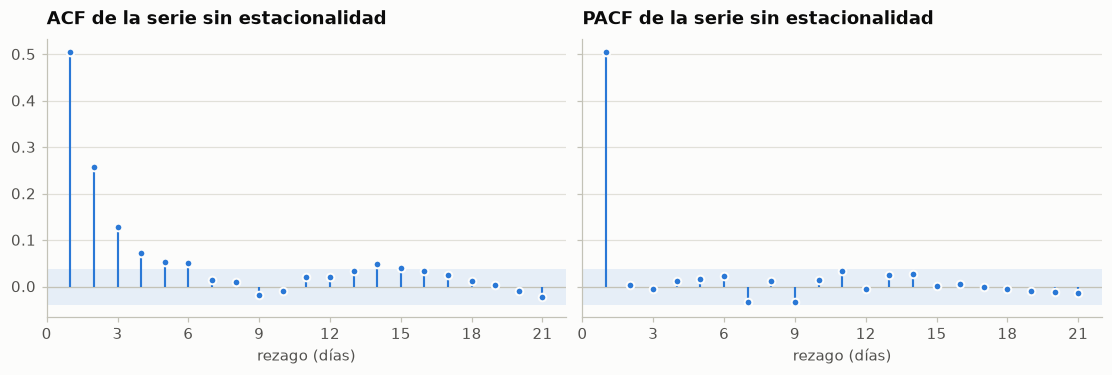

ACF: [0.5  0.26 0.13 0.07 0.05 0.05 0.01] 
PACF: [ 0.5   0.   -0.    0.01  0.02  0.02 -0.03]


In [9]:
ytr = y[:FIN_ENTRENAMIENTO]
Xtr = regresores(ytr.index, K=2)
m = ytr.notna()
clim_tr = sm.OLS(ytr[m], Xtr[m]).fit()
resid_tr = (ytr - Xtr @ clim_tr.params).interpolate(limit=3).dropna()

filas = []
for nombre, s in (("y (original)", ytr.interpolate(limit=3).dropna()), ("y sin estacionalidad", resid_tr)):
    adf = adfuller(s, autolag="AIC")
    kp = kpss(s, regression="c", nlags="auto")
    filas.append({"serie": nombre, "ADF estadístico": adf[0], "ADF p": adf[1], "KPSS estadístico": kp[0], "KPSS p": kp[1]})
display(pd.DataFrame(filas).set_index("serie").round(4))
print(f"La regresión armónica (K=2) + día de la semana explica R² = {clim_tr.rsquared:.1%} de la varianza diaria")

n_lags = 21
v_acf, v_pacf = acf(resid_tr, nlags=n_lags), pacf(resid_tr, nlags=n_lags)
banda = 1.96 / np.sqrt(len(resid_tr))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for ax, (nombre, vals) in zip(axs, (("ACF", v_acf), ("PACF", v_pacf))):
    lags = np.arange(1, n_lags + 1)
    ax.axhspan(-banda, banda, color=AZUL, alpha=0.10, lw=0)
    ax.axhline(0, color=EJE, lw=0.8)
    ax.vlines(lags, 0, vals[1:], color=AZUL, lw=1.4)
    ax.plot(lags, vals[1:], "o", color=AZUL, ms=5, mec=SUP, mew=1.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("rezago (días)")
    ax.set_title(f"{nombre} de la serie sin estacionalidad")
guardar(fig, "05_acf_pacf")
plt.show()
print("ACF:", np.round(v_acf[1:8], 2), "\nPACF:", np.round(v_pacf[1:8], 2))

**Lectura.**
- **Estacionariedad:** ADF rechaza la raíz unitaria y KPSS no rechaza la estacionariedad, así que $d = 0$. Diferenciar sería sobrediferenciar.
- **Orden:** sin estacionalidad, la ACF decae geométricamente y la PACF se corta después del rezago 1. Es la firma de un **AR(1)**: el "clima" de ozono de hoy se parece al de ayer, pero la memoria se pierde en pocos días.
- **Hipótesis:** la regresión armónica con errores AR(1) es la candidata principal. Abajo se compara contra alternativas.

## 5. Selección del modelo (validación)

- **Ajuste:** cada candidato se estima con datos hasta el fin de entrenamiento (2015-2021).
- **Validación:** con esos parámetros fijos se pronostica a 1 día cada fecha de 2022 y 2023. Se usan dos años porque con uno solo el orden de los candidatos cambiaba mucho de un año a otro.
- **Regla de elección:** menor RMSE de validación, sin margen de empate. Una versión anterior rompía los empates (dentro de 0.5 %) a favor del modelo con menos parámetros; al revisarla, esa regla elegía sistemáticamente un modelo peor en la prueba, así que se quitó.
- **Referencias:** para tener contexto también se evalúan la persistencia ($\hat y_t = y_{t-1}$), la climatología (media histórica por día del año) y un SARIMA "de libro" sin términos anuales.


In [10]:
v0, v1 = VALIDACION
obs_val = y[v0:v1]
filas = []
for K in (1, 2, 3, 4, 6):
    for dsem in (False, True):
        X = regresores(y.index, K, dsem)
        for orden in ((1, 0, 0), (2, 0, 0), (1, 0, 1)):
            r = ajustar(y, X, orden, FIN_ENTRENAMIENTO)
            mu, _, _ = un_paso(r, y, X, orden, (0, 0, 0, 0), v0, v1)
            e = (obs_val - mu).dropna()
            filas.append({"K": K, "dia_semana": dsem, "orden": orden, "parametros": len(r.params),
                          "AIC": r.aic, "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "n": len(e)})
grid = pd.DataFrame(filas).sort_values("RMSE").reset_index(drop=True)
elegido = grid.iloc[0]                 # menor RMSE de validación, sin margen de empate
K, DSEM, ORDEN = int(elegido["K"]), bool(elegido["dia_semana"]), tuple(elegido["orden"])
NOMBRE = f"Armónica K={K}{' + día sem.' if DSEM else ''} + ARIMA{ORDEN}"
display(grid.head(10).round(2))

# Referencias en el mismo periodo de validación
ref = {}
sar_v = ajustar(y, None, (1, 1, 1), FIN_ENTRENAMIENTO, (1, 0, 1, 7))
ref["SARIMA(1,1,1)(1,0,1)7 sin términos anuales"] = un_paso(sar_v, y, None, (1, 1, 1), (1, 0, 1, 7), v0, v1)[0]
ref["Climatología (día del año)"] = climatologia(y, FIN_ENTRENAMIENTO, y.index)[v0:v1]
ref["Persistencia (ayer)"] = y.shift(1)[v0:v1]
tabla_val = pd.DataFrame({n: {"MAE": (obs_val - f).dropna().abs().mean(),
                              "RMSE": np.sqrt(((obs_val - f).dropna() ** 2).mean())} for n, f in ref.items()}).T
tabla_val.loc[NOMBRE] = [elegido["MAE"], elegido["RMSE"]]
display(tabla_val.sort_values("RMSE").round(2))
print(f"Elegido: {NOMBRE}  (RMSE validación {elegido['RMSE']:.2f} ppb, {int(elegido['parametros'])} parámetros)")

,K,dia_semana,orden,parametros,AIC,MAE,RMSE,n
0,2,True,"(1, 0, 0)",13,23147.63,16.70,21.26,730
1,2,True,"(2, 0, 0)",14,23149.59,16.71,21.26,730
2,2,True,"(1, 0, 1)",14,23149.58,16.70,21.26,730
3,2,False,"(1, 0, 0)",7,23145.59,16.77,21.30,730
4,2,False,"(2, 0, 0)",8,23147.55,16.77,21.30,730
5,2,False,"(1, 0, 1)",8,23147.55,16.77,21.30,730
6,4,True,"(2, 0, 0)",18,23139.32,16.79,21.37,730
7,4,True,"(1, 0, 0)",17,23137.35,16.79,21.37,730
8,4,True,"(1, 0, 1)",18,23139.32,16.79,21.37,730
9,1,True,"(1, 0, 0)",11,23153.08,16.74,21.38,730


,MAE,RMSE
"Armónica K=2 + día sem. + ARIMA(1, 0, 0)",16.70,21.26
"SARIMA(1,1,1)(1,0,1)7 sin términos anuales",17.02,21.64
Persistencia (ayer),18.95,24.31
Climatología (día del año),22.11,27.60


Elegido: Armónica K=2 + día sem. + ARIMA(1, 0, 0)  (RMSE validación 21.26 ppb, 13 parámetros)


## 6. Diagnóstico del modelo elegido

Se reestima con entrenamiento + validación. Si el modelo está bien especificado, los residuos deben parecerse a ruido blanco: sin autocorrelación (Ljung-Box) y aproximadamente normales.

,coef,error_est,p
const,95.61,1.29,0.00e+00
sin1,10.94,1.11,0.00e+00
cos1,-8.22,1.14,0.00e+00
sin2,-2.52,1.10,2.30e-02
cos2,-4.06,1.15,0.00e+00
mar,3.87,1.22,1.00e-03
mie,3.32,1.43,2.00e-02
jue,3.23,1.53,3.50e-02
vie,2.54,1.56,1.03e-01
sab,3.41,1.49,2.20e-02


φ (AR1) = 0.512 → vida media del choque ≈ 1.0 días


,lb_stat,lb_pvalue
rezago,,
7,4.09,0.77
14,18.68,0.18
28,23.50,0.71


Jarque-Bera = 16.2 (p = 0.000306) | asimetría -0.16 | curtosis en exceso 0.13


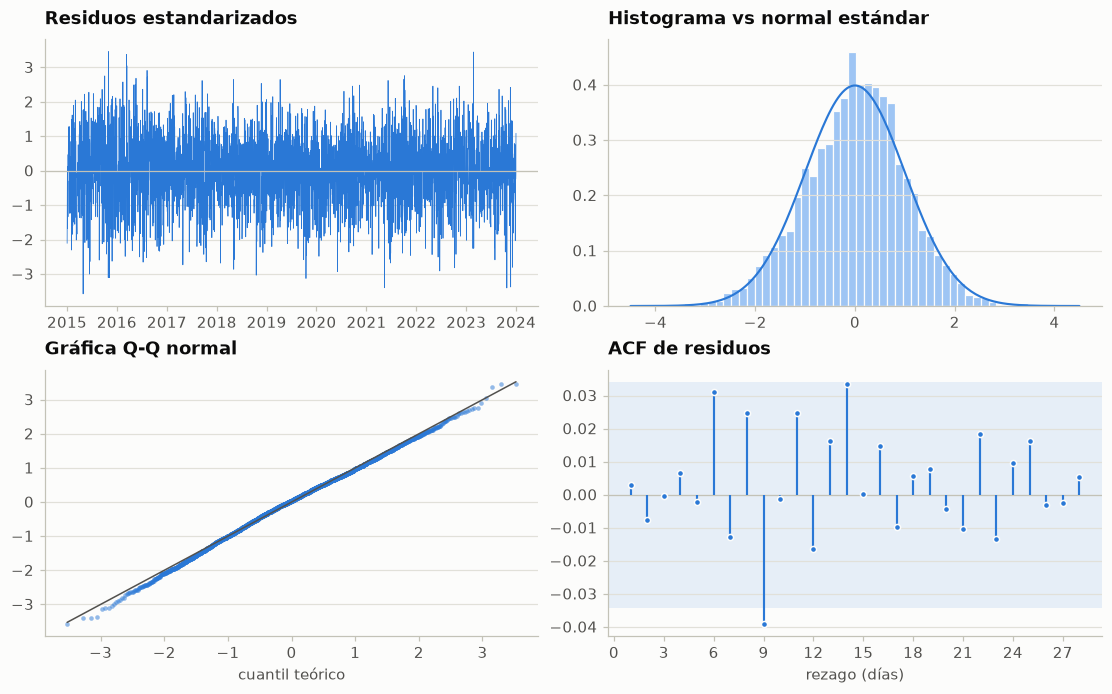

In [11]:
FIN_AJUSTE = VALIDACION[1]
X = regresores(y.index, K, DSEM)
final = ajustar(y, X, ORDEN, FIN_AJUSTE)
coefs = pd.DataFrame({"coef": final.params, "error_est": final.bse, "p": final.pvalues})
display(coefs.round(3))
phi = final.params.get("ar.L1", np.nan)
print(f"φ (AR1) = {phi:.3f} → vida media del choque ≈ {np.log(0.5) / np.log(phi):.1f} días")

e_std = (final.resid / np.sqrt(final.params["sigma2"])).iloc[1:].dropna()
lb = acorr_ljungbox(e_std, lags=[7, 14, 28], return_df=True)
lb.index.name = "rezago"
display(lb.round(3))
jb = stats.jarque_bera(e_std)
print(f"Jarque-Bera = {jb.statistic:.1f} (p = {jb.pvalue:.3g}) | asimetría {stats.skew(e_std):.2f} | "
      f"curtosis en exceso {stats.kurtosis(e_std):.2f}")

fig, axs = plt.subplots(2, 2, figsize=(10, 6.2))
axs[0, 0].plot(e_std.index, e_std, color=AZUL, lw=0.5)
axs[0, 0].axhline(0, color=EJE, lw=0.8)
axs[0, 0].set_title("Residuos estandarizados")
axs[0, 1].hist(e_std, bins=45, density=True, color=AZUL_CLARO, edgecolor=SUP, linewidth=0.8)
xx = np.linspace(-4.5, 4.5, 200)
axs[0, 1].plot(xx, stats.norm.pdf(xx), color=AZUL, lw=1.4)
axs[0, 1].set_title("Histograma vs normal estándar")
(osm, osr), (pend, inter, _) = stats.probplot(e_std, dist="norm")
axs[1, 0].plot(osm, osr, "o", color=AZUL, ms=3, alpha=0.5, mec="none")
axs[1, 0].plot(osm, pend * osm + inter, color=TINTA2, lw=1)
axs[1, 0].set_title("Gráfica Q-Q normal")
axs[1, 0].set_xlabel("cuantil teórico")
r_acf = acf(e_std, nlags=28)[1:]
lags = np.arange(1, 29)
axs[1, 1].axhspan(-1.96 / np.sqrt(len(e_std)), 1.96 / np.sqrt(len(e_std)), color=AZUL, alpha=0.10, lw=0)
axs[1, 1].axhline(0, color=EJE, lw=0.8)
axs[1, 1].vlines(lags, 0, r_acf, color=AZUL, lw=1.4)
axs[1, 1].plot(lags, r_acf, "o", color=AZUL, ms=4, mec=SUP, mew=1)
axs[1, 1].xaxis.set_major_locator(MaxNLocator(integer=True))
axs[1, 1].set_title("ACF de residuos")
axs[1, 1].set_xlabel("rezago (días)")
guardar(fig, "06_diagnostico_residuos")
plt.show()

**Lectura.**
- **Autocorrelación:** Ljung-Box no rechaza ruido blanco al 5 % en los rezagos 7, 14 y 28 (p = 0.77, 0.18 y 0.71). El modelo ya extrajo casi toda la estructura temporal.
- **Día de la semana:** de martes a domingo hay entre 2.5 y 3.9 ppb más ozono que el lunes (la referencia). El efecto es chico pero consistente, y mejoró el pronóstico en validación.
- **Normalidad:** las colas se desvían algo de la normal (Jarque-Bera rechaza, aunque la asimetría −0.16 y la curtosis en exceso 0.13 son pequeñas). Por eso la calibración de los intervalos se verifica empíricamente en la prueba en lugar de suponerla.


## 7. Prueba fuera de muestra

Desde el inicio de la prueba ya no se elige ni se reestima nada. Cada día se pronostica con la información disponible hasta el día anterior. Las métricas se calculan sobre los mismos días para todos los modelos.

**MASE** = MAE / MAE de la persistencia en entrenamiento. Valores menores a 1 significan que el modelo le gana a "mañana igual que hoy".

In [12]:
FIN = y.index[-1]
obs = y[INICIO_PRUEBA:FIN]
mu, se, completo = un_paso(final, y, X, ORDEN, (0, 0, 0, 0), INICIO_PRUEBA, FIN)
sar = ajustar(y, None, (1, 1, 1), FIN_AJUSTE, (1, 0, 1, 7))
mu_sar, _, completo_sar = un_paso(sar, y, None, (1, 1, 1), (1, 0, 1, 7), INICIO_PRUEBA, FIN)
print("Parámetros del SARIMA(1,1,1)(1,0,1)7:", sar.params.round(3).to_dict())
clim = climatologia(y, FIN_AJUSTE, y.index)

pron = pd.DataFrame({"observado": obs, NOMBRE: mu, "SARIMA(1,1,1)(1,0,1)7": mu_sar,
                     "Persistencia (ayer)": y.shift(1)[INICIO_PRUEBA:FIN],
                     "Climatología (día del año)": clim[INICIO_PRUEBA:FIN],
                     "Ingenuo semanal (hace 7 días)": y.shift(7)[INICIO_PRUEBA:FIN]})
comun = pron.dropna()
escala = (y[:FIN_AJUSTE] - y[:FIN_AJUSTE].shift(1)).abs().mean()


def metricas(o, f):
    e = o - f
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "MASE": e.abs().mean() / escala, "sesgo": e.mean()}


tabla = pd.DataFrame({c: metricas(comun["observado"], comun[c]) for c in pron.columns[1:]}).T.sort_values("RMSE")
print(f"Prueba: {comun.index.min():%Y-%m-%d} a {comun.index.max():%Y-%m-%d} | {len(comun)} días comparables")
display(tabla.round(2))


def diebold_mariano(e1, e2):
    # H0: igual error cuadrático medio. Horizonte 1 con corrección de Harvey-Leybourne-Newbold.
    d = (e1 ** 2 - e2 ** 2).dropna()
    n = len(d)
    dm = d.mean() / np.sqrt(d.var(ddof=1) / n) * np.sqrt((n - 1) / n)
    return dm, 2 * stats.t.sf(abs(dm), n - 1)


e_mod = comun["observado"] - comun[NOMBRE]
dm_tabla = pd.DataFrame({c: dict(zip(["DM", "p"], diebold_mariano(comun["observado"] - comun[c], e_mod)))
                         for c in pron.columns[2:]}).T
display(dm_tabla.round(4))

z = {80: 1.281552, 95: 1.959964}
cob = {f"cobertura {k} %": ((obs >= mu - v * se) & (obs <= mu + v * se))[obs.notna()].mean() for k, v in z.items()}
print({k: f"{v:.1%}" for k, v in cob.items()})
pron.assign(error_est=se).to_csv(RES / "pronosticos_prueba.csv", float_format="%.2f")
tabla.to_csv(RES / "metricas_prueba.csv", float_format="%.3f")

Parámetros del SARIMA(1,1,1)(1,0,1)7: {'ar.L1': 0.495, 'ma.L1': -0.96, 'ar.S.L7': -0.735, 'ma.S.L7': 0.713, 'sigma2': 500.521}
Prueba: 2024-01-01 a 2026-10-21 | 1005 días comparables


,MAE,RMSE,MASE,sesgo
"Armónica K=2 + día sem. + ARIMA(1, 0, 0)",17.46,22.02,0.88,2.00
"SARIMA(1,1,1)(1,0,1)7",17.60,22.34,0.89,0.08
Persistencia (ayer),19.29,24.92,0.98,-0.08
Climatología (día del año),21.65,26.97,1.10,4.26
Ingenuo semanal (hace 7 días),27.65,34.84,1.40,0.08


,DM,p
"SARIMA(1,1,1)(1,0,1)7",2.06,0.04
Persistencia (ayer),6.76,0.00
Climatología (día del año),10.28,0.00
Ingenuo semanal (hace 7 días),13.57,0.00


{'cobertura 80 %': '80.1%', 'cobertura 95 %': '94.1%'}


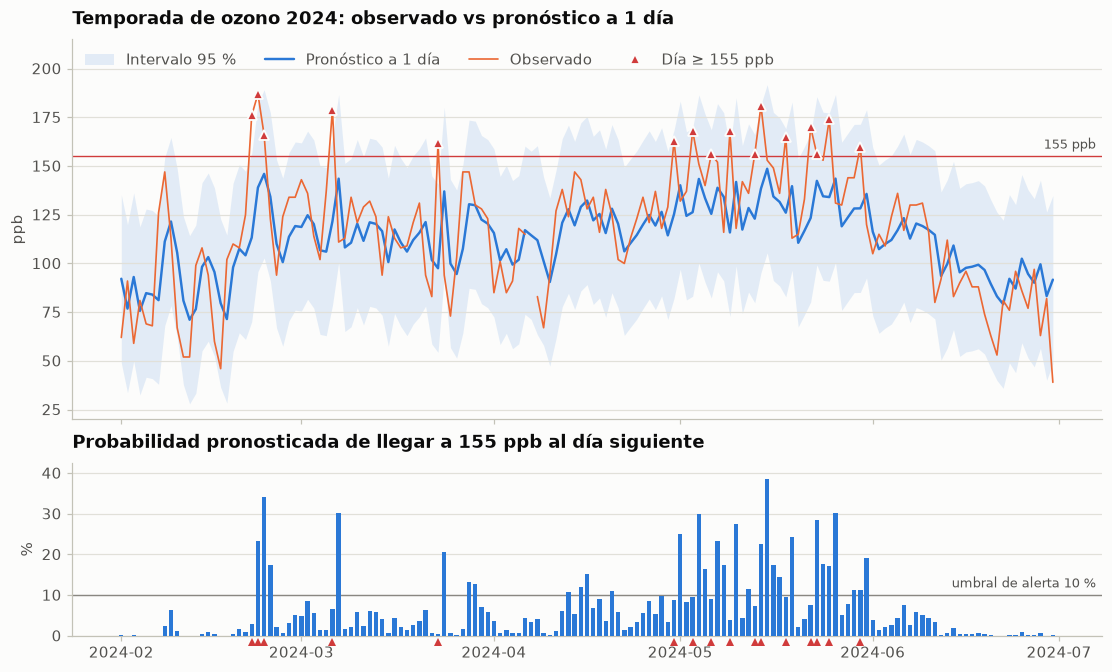

In [13]:
prob155 = pd.Series(stats.norm.sf((UMBRAL_FASE1 - mu) / se), index=mu.index)
anio_ventana = pd.Timestamp(INICIO_PRUEBA).year
v_ini, v_fin = f"{anio_ventana}-02-01", f"{anio_ventana}-06-30"
o, f, s, p = obs[v_ini:v_fin], mu[v_ini:v_fin], se[v_ini:v_fin], prob155[v_ini:v_fin]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.0), sharex=True, height_ratios=[2.2, 1])
ax1.fill_between(f.index, f - 1.96 * s, f + 1.96 * s, color=AZUL, alpha=0.12, lw=0, label="Intervalo 95 %")
ax1.plot(f.index, f, color=AZUL, lw=1.6, label="Pronóstico a 1 día")
ax1.plot(o.index, o, color=NARANJA, lw=1.1, label="Observado")
ev = o[o >= UMBRAL_FASE1]
ax1.plot(ev.index, ev, "^", color=CRITICO, ms=7, mec=SUP, mew=1.2, label=f"Día ≥ {UMBRAL_FASE1} ppb")
linea_umbral(ax1, UMBRAL_FASE1, CRITICO, f"{UMBRAL_FASE1} ppb")
ax1.set_ylabel("ppb")
ax1.set_title(f"Temporada de ozono {anio_ventana}: observado vs pronóstico a 1 día")
ax1.legend(loc="upper left", ncols=4)
ax1.set_ylim(20, 215)
ax2.bar(p.index, p * 100, width=0.7, color=AZUL, zorder=3)
ax2.set_ylim(0, max(40, p.max() * 110))
ax2.axhline(10, color=TENUE, lw=0.9)
ax2.annotate("umbral de alerta 10 %", xy=(1, 10), xycoords=("axes fraction", "data"), xytext=(-4, 3),
             textcoords="offset points", ha="right", va="bottom", color=TINTA2, fontsize=8.5)
for d in ev.index:
    ax2.plot(d, -1.5, "^", color=CRITICO, ms=5, clip_on=False, mec="none")
ax2.set_ylabel("%")
ax2.set_title(f"Probabilidad pronosticada de llegar a {UMBRAL_FASE1} ppb al día siguiente")
guardar(fig, "07_prueba_temporada")
plt.show()

**Lectura.**
- **Precisión:** a un día, el modelo tiene el menor MAE y RMSE de todos (17.5 y 22.0 ppb). Frente a la persistencia, el RMSE baja ~12 % y la diferencia es significativa (Diebold-Mariano, p < 0.001). También le gana al SARIMA semanal "de libro" (p = 0.04).
- **Calibración:** el intervalo del 95 % cubre 94 % de los días y el del 80 % cubre 80 %, así que la incertidumbre que reporta es confiable.
- **Sesgo estacional:** el modelo subestima mayo (error medio ≈ +9 ppb) y sobreestima junio (≈ −8 ppb): dos armónicos todavía no reproducen del todo lo agudo del pico de la temporada. Con K = 6 ese sesgo baja a +6/−5 ppb, pero ese modelo no ganó en validación y elegirlo por cómo le va en la prueba sería contaminar la prueba.
- **Límites:** sigue bien el nivel de la temporada, pero subestima los picos. Los días de 170-185 ppb quedan cerca del borde superior del intervalo, porque un AR(1) no puede anticipar el cambio meteorológico que los dispara.


## 8. ¿Hasta cuántos días sirve el pronóstico?

Desde cada día de la prueba se pronostica 1 a 7 días adelante sin ver los datos intermedios (pronóstico dinámico).

días adelante,1,2,3,4,5,6,7
"Armónica K=2 + día sem. + ARIMA(1, 0, 0)",17.4,20.0,20.9,21.2,21.3,21.3,21.3
"SARIMA(1,1,1)(1,0,1)7",17.6,20.2,21.2,21.5,21.7,21.9,22.0
Persistencia (ayer),19.3,23.9,25.9,26.8,27.8,27.9,27.6
Climatología (día del año),21.6,21.6,21.7,21.7,21.7,21.7,21.7


Ventaja sobre la climatología (ppb): [4.2, 1.6, 0.8, 0.5, 0.4, 0.3, 0.3]


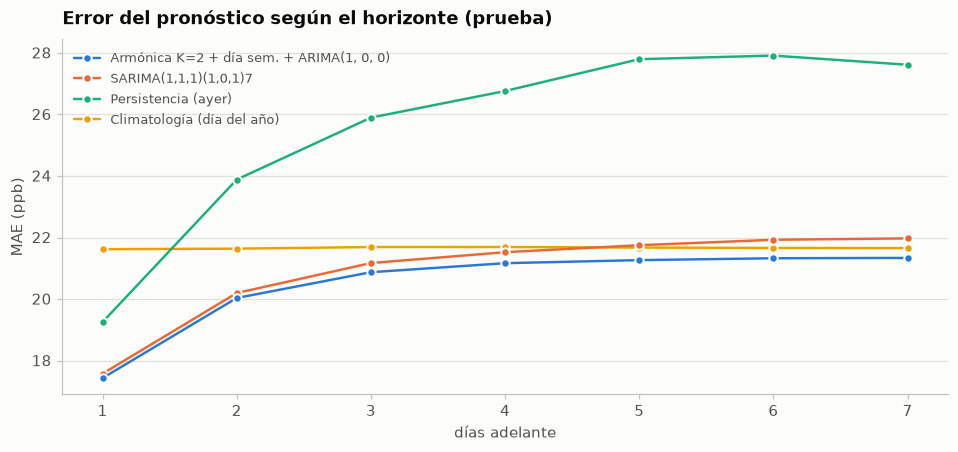

In [14]:
H = 7
origenes = pd.date_range(pd.Timestamp(INICIO_PRUEBA) - pd.Timedelta(days=1), FIN - pd.Timedelta(days=H), freq="D")
err = {n: np.full((len(origenes), H), np.nan) for n in (NOMBRE, "SARIMA(1,1,1)(1,0,1)7", "Persistencia (ayer)", "Climatología (día del año)")}
for i, o0 in enumerate(origenes):
    a, b = o0 + pd.Timedelta(days=1), o0 + pd.Timedelta(days=H)
    v = y[a:b].to_numpy()
    err[NOMBRE][i] = v - completo.get_prediction(start=a, end=b, dynamic=0).predicted_mean.to_numpy()
    err["SARIMA(1,1,1)(1,0,1)7"][i] = v - completo_sar.get_prediction(start=a, end=b, dynamic=0).predicted_mean.to_numpy()
    err["Persistencia (ayer)"][i] = v - y[o0]
    err["Climatología (día del año)"][i] = v - clim[a:b].to_numpy()
mae_h = pd.DataFrame({n: np.nanmean(np.abs(e), axis=0) for n, e in err.items()}, index=pd.RangeIndex(1, H + 1, name="días adelante"))
display(mae_h.T.round(1))
print("Ventaja sobre la climatología (ppb):", (mae_h["Climatología (día del año)"] - mae_h[NOMBRE]).round(1).tolist())
mae_h.to_csv(RES / "mae_por_horizonte.csv", float_format="%.3f")

fig, ax = plt.subplots(figsize=(8.6, 4.0))
estilos = {NOMBRE: AZUL, "SARIMA(1,1,1)(1,0,1)7": NARANJA, "Persistencia (ayer)": AQUA, "Climatología (día del año)": AMARILLO}
lineas = {}
for n in reversed(list(estilos)):
    lineas[n], = ax.plot(mae_h.index, mae_h[n], color=estilos[n], lw=1.6, marker="o", ms=5.5, mec=SUP, mew=1.3, label=n)
ax.set_xlabel("días adelante")
ax.set_ylabel("MAE (ppb)")
ax.set_title("Error del pronóstico según el horizonte (prueba)")
ax.legend(handles=[lineas[n] for n in estilos], loc="upper left", fontsize=8.5)
guardar(fig, "08_mae_horizonte")
plt.show()

**Lectura.**
- **Horizonte útil:** el modelo es el mejor en todos los horizontes. Su ventaja sobre la climatología baja de 4.2 ppb a 1 día a 1.6 a 2 días, 0.8 a 3 y 0.5 a 4; es estadísticamente significativa hasta el día 4 (Diebold-Mariano p = 0.001 a 3 días y 0.03 a 4) y deja de serlo del día 5 en adelante. Con $\phi \approx 0.5$, un choque pierde la mitad de su efecto en ~1 día ($0.51^3 \approx 0.13$). En la práctica el valor está en 1-2 días; de 3 a 4 la mejora es marginal.
- **Referencia honesta:** la climatología es la media histórica por día del año, no la parte armónica del propio modelo. Es más exigente (RMSE 27.0 frente a 27.3 de los armónicos en la prueba), así que la ventaja que se reporta no está inflada.
- **SARIMA "de libro" a un día:** queda cerca, pero ya es significativamente peor (p = 0.04).
- **SARIMA "de libro" con horizonte:** a partir del día 6 es peor que la climatología, porque al no tener media estacional no regresa a ella.
- **Sobrediferenciación:** sus parámetros la delatan. El MA(1) sale ≈ −0.96, casi cancelando la diferencia, y el AR y el MA estacionales casi se anulan entre sí.


## 9. Alerta de contingencia

Con errores aproximadamente normales, la probabilidad de llegar al umbral mañana es

$$P(y_{t+1} \ge 155 \mid \mathcal{F}_t) = 1 - \Phi\!\left(\frac{155 - \hat y_{t+1}}{\hat\sigma_{t+1}}\right)$$

Se evalúa con dos medidas:
- **AUC:** capacidad de ordenar días con evento por encima de días sin evento.
- **Brier y su skill score (BSS):** comparados contra la frecuencia histórica del evento.

In [15]:
def auc(score, etiqueta):
    d = pd.DataFrame({"s": score, "l": etiqueta}).dropna()
    pos, neg = (d["l"] == 1).sum(), (d["l"] == 0).sum()
    r = d["s"].rank()
    return (r[d["l"] == 1].sum() - pos * (pos + 1) / 2) / (pos * neg)


ok = obs.notna()
resumen_eventos, tablas_corte = [], {}
for umbral in (UMBRAL_FASE1, LIMITE_NOM):
    etiqueta = (obs >= umbral).astype(float) if umbral == UMBRAL_FASE1 else (obs > umbral).astype(float)
    prob = pd.Series(stats.norm.sf((umbral - mu) / se), index=mu.index)
    base = (y[:FIN_AJUSTE] >= umbral).mean() if umbral == UMBRAL_FASE1 else (y[:FIN_AJUSTE] > umbral).mean()
    brier = ((prob - etiqueta) ** 2)[ok].mean()
    brier_ref = ((base - etiqueta) ** 2)[ok].mean()
    resumen_eventos.append({"evento": f"máximo {'≥' if umbral == UMBRAL_FASE1 else '>'} {umbral} ppb",
                            "días con evento": int(etiqueta[ok].sum()), "días evaluados": int(ok.sum()),
                            "AUC": auc(prob[ok], etiqueta[ok]), "Brier": brier, "Brier referencia": brier_ref,
                            "BSS": 1 - brier / brier_ref})
    filas = []
    for corte in ((0.05, 0.1, 0.2, 0.3) if umbral == UMBRAL_FASE1 else (0.3, 0.5, 0.7)):
        alerta, real = (prob >= corte)[ok], etiqueta[ok] == 1
        vp, fp, fn = int((alerta & real).sum()), int((alerta & ~real).sum()), int((~alerta & real).sum())
        filas.append({"alerta si p ≥": corte, "alertas": vp + fp, "aciertos": vp, "falsas": fp, "omitidos": fn,
                      "precisión": vp / max(vp + fp, 1), "recall": vp / max(vp + fn, 1)})
    tablas_corte[umbral] = pd.DataFrame(filas)
display(pd.DataFrame(resumen_eventos).set_index("evento").round(3))
print(f"Calibración global ≥ {UMBRAL_FASE1} ppb: eventos esperados (suma de probabilidades) = {prob155[ok].sum():.1f} "
      f"vs observados = {int((obs[ok] >= UMBRAL_FASE1).sum())} | probabilidad máxima emitida = {prob155[ok].max():.0%}")
print(f"Cortes de alerta para ≥ {UMBRAL_FASE1} ppb:")
display(tablas_corte[UMBRAL_FASE1].round(2))

,días con evento,días evaluados,AUC,Brier,Brier referencia,BSS
evento,,,,,,
máximo ≥ 155 ppb,30,1022,0.91,0.03,0.03,0.12
máximo > 90 ppb,712,1022,0.81,0.16,0.21,0.26


Calibración global ≥ 155 ppb: eventos esperados (suma de probabilidades) = 27.9 vs observados = 30 | probabilidad máxima emitida = 39%
Cortes de alerta para ≥ 155 ppb:


,alerta si p ≥,alertas,aciertos,falsas,omitidos,precisión,recall
0,0.05,172,25,147,5,0.15,0.83
1,0.10,80,14,66,16,0.18,0.47
2,0.20,20,5,15,25,0.25,0.17
3,0.30,4,1,3,29,0.25,0.03


**Lectura.**
- **Discriminación:** para el nivel de Fase I el modelo **ordena bien el riesgo** (AUC ≈ 0.91), aunque la probabilidad nunca pasa de ~40 %. Hay que decirlo con cuidado: el máximo de hoy por sí solo (persistencia) ya ordena el riesgo de mañana casi igual de bien (AUC ≈ 0.90); lo que el ARIMA aporta es la probabilidad y el intervalo, no mucha discriminación extra.
- **Calibración:** el modelo **subestima un poco** el riesgo de extremos. La suma de probabilidades da ~28 días esperados y ocurrieron 30. La cola superior es más pesada que la normal y 2024 fue un año atípicamente alto (16 días frente a ~2 % de los días en el entrenamiento). Para usarlo como alerta habría que recalibrar la probabilidad, por ejemplo con el sesgo por mes.
- **Como alarma binaria no sirve:** con un corte del 10 % captura 14 de los 30 días ≥ 155 ppb, pero 66 de las 80 alertas son falsas.
- **Uso recomendado:** como semáforo de riesgo para el día siguiente, no como predicción de contingencia.
- **Qué falta:** el salto de calidad pide variables meteorológicas pronosticadas (temperatura máxima, radiación, viento), que un ARIMA univariado no ve.


## 10. Extensión: pronóstico horario con SARIMA (s = 24)

A escala horaria el ciclo diario es la estacionalidad dominante. Por eso aquí sí conviene un SARIMA con diferencia estacional en el rezago 24.
- **Serie:** el máximo horario de la red.
- **Ajuste:** marzo-abril.
- **Evaluación:** cada medianoche de mayo se pronostican las 24 horas siguientes, contra repetir el mismo día de ayer.

,AIC,MAE 24 h,MAE ingenuo (ayer),mejora vs ingenuo
modelo,,,,
"SARIMA(1, 0, 1)x(0, 1, 1, 24)",9622.52,10.75,12.62,0.15
"SARIMA(2, 0, 0)x(0, 1, 1, 24)",9624.80,10.81,12.62,0.14
"SARIMA(2, 0, 1)x(1, 1, 1, 24)",9622.59,10.82,12.62,0.14


Elegido: SARIMA(1, 0, 1)x(0, 1, 1, 24) | parámetros: {'ar.L1': 0.82, 'ma.L1': 0.23, 'ma.S.L24': -0.94, 'sigma2': 55.43}


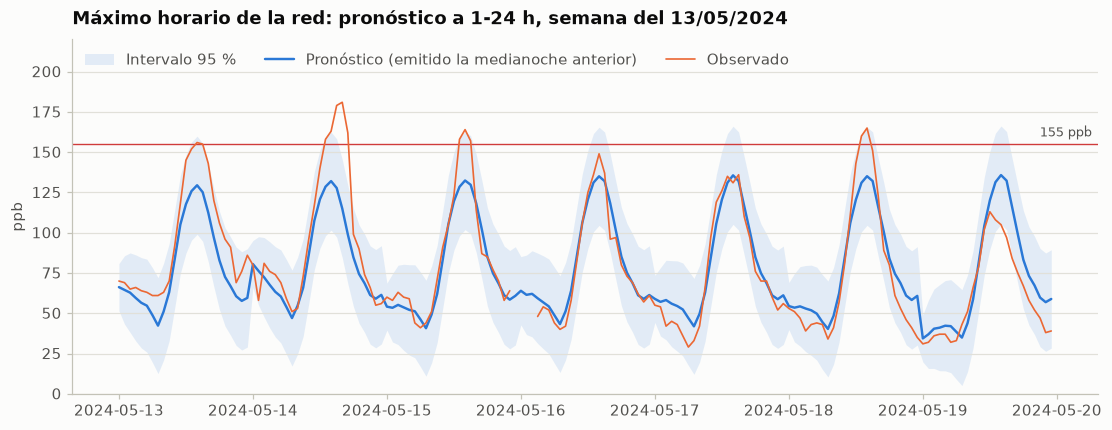

In [16]:
anio_h = pd.Timestamp(INICIO_PRUEBA).year
yh = horario["maximo"]
H_INI, H_FIN_AJ, H_FIN = f"{anio_h}-03-01", f"{anio_h}-04-30 23:00", f"{anio_h}-05-31 23:00"
yh_v = yh[H_INI:H_FIN]
orig_h = pd.date_range(f"{anio_h}-04-30 23:00", f"{anio_h}-05-30 23:00", freq="D")
filas, guardados = [], {}
for orden_h, est_h in (((1, 0, 1), (0, 1, 1, 24)), ((2, 0, 0), (0, 1, 1, 24)), ((2, 0, 1), (1, 1, 1, 24))):
    rh = SARIMAX(yh_v[:H_FIN_AJ], order=orden_h, seasonal_order=est_h).fit(disp=False, maxiter=100)
    fh = SARIMAX(yh_v, order=orden_h, seasonal_order=est_h).filter(rh.params)
    e_m, e_n, piezas = [], [], []
    for o0 in orig_h:
        a, b = o0 + pd.Timedelta(hours=1), o0 + pd.Timedelta(hours=24)
        pr = fh.get_prediction(start=a, end=b, dynamic=0)
        v = yh_v[a:b]
        e_m.append((v - pr.predicted_mean).to_numpy())
        e_n.append((v.to_numpy() - yh_v[a - pd.Timedelta(hours=24):b - pd.Timedelta(hours=24)].to_numpy()))
        piezas.append(pd.DataFrame({"pron": pr.predicted_mean, "se": pr.se_mean}))
    filas.append({"modelo": f"SARIMA{orden_h}x{est_h}", "AIC": rh.aic, "MAE 24 h": np.nanmean(np.abs(e_m)),
                  "MAE ingenuo (ayer)": np.nanmean(np.abs(e_n))})
    guardados[filas[-1]["modelo"]] = (rh, pd.concat(piezas))
tabla_h = pd.DataFrame(filas).set_index("modelo")
tabla_h["mejora vs ingenuo"] = 1 - tabla_h["MAE 24 h"] / tabla_h["MAE ingenuo (ayer)"]
display(tabla_h.round(3))
mejor_h = tabla_h["MAE 24 h"].idxmin()
rh, serie_h = guardados[mejor_h]
print(f"Elegido: {mejor_h} | parámetros: {rh.params.round(2).to_dict()}")

sem_ini = pd.Timestamp(f"{anio_h}-05-13")
sem = slice(sem_ini, sem_ini + pd.Timedelta(days=7) - pd.Timedelta(hours=1))
fig, ax = plt.subplots(figsize=(10, 3.8))
ps = serie_h.loc[sem]
ax.fill_between(ps.index, ps["pron"] - 1.96 * ps["se"], ps["pron"] + 1.96 * ps["se"], color=AZUL, alpha=0.12, lw=0, label="Intervalo 95 %")
ax.plot(ps.index, ps["pron"], color=AZUL, lw=1.6, label="Pronóstico (emitido la medianoche anterior)")
ax.plot(yh_v.loc[sem].index, yh_v.loc[sem], color=NARANJA, lw=1.1, label="Observado")
linea_umbral(ax, UMBRAL_FASE1, CRITICO, f"{UMBRAL_FASE1} ppb")
ax.set_ylabel("ppb")
ax.set_ylim(0, 220)
ax.set_title(f"Máximo horario de la red: pronóstico a 1-24 h, semana del {sem_ini:%d/%m/%Y}")
ax.legend(loc="upper left", ncols=3)
guardar(fig, "09_sarima_horario")
plt.show()

**Lectura.**
- **Desempeño:** el SARIMA horario reduce el error frente a "igual que ayer a la misma hora".
- **Estacionalidad casi determinista:** el MA estacional cercano a -1 indica que la diferencia estacional casi se cancela, es decir, el ciclo diario es muy regular.
- **Alternativa:** términos de Fourier diarios en vez de la diferencia en el rezago 24, igual que en el modelo diario.

## 11. Pronóstico de la próxima semana

El modelo elegido se reestima con todos los datos y se pronostican los 7 días siguientes al último dato disponible.

In [17]:
r_todo = ajustar(y, X, ORDEN, FIN)
fechas = pd.date_range(FIN + pd.Timedelta(days=1), periods=7, freq="D")
fc = r_todo.get_forecast(steps=7, exog=regresores(fechas, K, DSEM))
mu_f, se_f = fc.predicted_mean, fc.se_mean
proximos = pd.DataFrame({"pronóstico (ppb)": mu_f, "inf 80 %": mu_f - z[80] * se_f, "sup 80 %": mu_f + z[80] * se_f,
                         "inf 95 %": mu_f - z[95] * se_f, "sup 95 %": mu_f + z[95] * se_f,
                         f"P(≥{UMBRAL_FASE1})": stats.norm.sf((UMBRAL_FASE1 - mu_f) / se_f)})
proximos.index.name = "fecha"
display(proximos.round(2))
proximos.to_csv(RES / "pronostico_proxima_semana.csv", float_format="%.3f")
print(f"Pronóstico emitido con datos hasta {FIN:%Y-%m-%d}")

,pronóstico (ppb),inf 80 %,sup 80 %,inf 95 %,sup 95 %,P(≥155)
fecha,,,,,,
2026-11-10,97.10,65.25,128.95,48.38,145.81,0.01
2026-11-11,93.62,60.82,126.41,43.46,143.77,0.01
2026-11-12,91.35,58.30,124.40,40.81,141.89,0.01
2026-11-13,89.50,56.38,122.62,38.85,140.15,0.01
2026-11-14,89.73,56.59,122.87,39.05,140.41,0.01
2026-11-15,87.41,54.27,120.56,36.72,138.10,0.00
2026-11-16,84.66,51.51,117.80,33.97,135.35,0.00


Pronóstico emitido con datos hasta 2026-11-09


In [18]:
fila_mod = tabla.loc[NOMBRE]
fila_per = tabla.loc["Persistencia (ayer)"]
ev155 = pd.DataFrame(resumen_eventos).set_index("evento").iloc[0]
resumen = {
    "periodo_datos": f"{y.index.min():%Y-%m-%d} a {FIN:%Y-%m-%d}",
    "dias_con_dato": int(y.notna().sum()),
    "pct_dias_sobre_nom": round(100 * float((y > LIMITE_NOM).mean() / y.notna().mean()), 1),
    "modelo": NOMBRE, "phi_ar1": round(float(phi), 3),
    "prueba": f"{comun.index.min():%Y-%m-%d} a {comun.index.max():%Y-%m-%d} ({len(comun)} días)",
    "MAE_modelo": round(float(fila_mod["MAE"]), 2), "RMSE_modelo": round(float(fila_mod["RMSE"]), 2),
    "RMSE_persistencia": round(float(fila_per["RMSE"]), 2),
    "mejora_RMSE_vs_persistencia_pct": round(100 * (1 - fila_mod["RMSE"] / fila_per["RMSE"]), 1),
    "DM_p_vs_persistencia": f"{dm_tabla.loc['Persistencia (ayer)', 'p']:.1e}",
    "cobertura_95": round(float(cob["cobertura 95 %"]), 3),
    "eventos_155_prueba": int(ev155["días con evento"]), "AUC_155": round(float(ev155["AUC"]), 3),
    "BSS_155": round(float(ev155["BSS"]), 3),
}
(RES / "resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")
for k, v in resumen.items():
    print(f"{k:<34} {v}")

periodo_datos                      2015-01-01 a 2026-11-09
dias_con_dato                      4309
pct_dias_sobre_nom                 64.8
modelo                             Armónica K=2 + día sem. + ARIMA(1, 0, 0)
phi_ar1                            0.512
prueba                             2024-01-01 a 2026-10-21 (1005 días)
MAE_modelo                         17.46
RMSE_modelo                        22.02
RMSE_persistencia                  24.92
mejora_RMSE_vs_persistencia_pct    11.7
DM_p_vs_persistencia               2.4e-11
cobertura_95                       0.941
eventos_155_prueba                 30
AUC_155                            0.912
BSS_155                            0.115


## 12. Conclusiones

1. **El problema es crónico, no episódico.** El máximo de la red rebasa el límite horario de la NOM (90 ppb) en más de 6 de cada 10 días con dato. El nivel de Fase I (≥ 155 ppb) se concentra en marzo-mayo, a las 14-17 h, en el sur y suroeste de la cuenca.
2. **Estructura simple.** La serie diaria es estacionaria ($d=0$). Quitando la estacionalidad anual (dos armónicos de Fourier) y el día de la semana queda un **AR(1)** con $\phi \approx 0.5$, y los residuos pasan Ljung-Box.
3. **Le gana a las referencias, con margen modesto.** En la prueba fuera de muestra, el RMSE es ~12 % menor que la persistencia y la diferencia es significativa (Diebold-Mariano, p < 0.001). También supera al SARIMA semanal "de libro" (p = 0.04). Los intervalos del 80 % y 95 % están bien calibrados.
4. **Horizonte útil de 1-2 días, ventaja significativa hasta 4.** Frente a la climatología por día del año, la ventaja es de 4.2 ppb a 1 día, 0.8 a 3 y 0.5 a 4; del día 5 en adelante no es distinguible de cero.
5. **Sirve como semáforo de riesgo, no como alarma.** Discrimina los días ≥ 155 ppb (AUC ≈ 0.91, casi lo mismo que la persistencia), pero con baja precisión y **subestimando un poco su frecuencia** (28 esperados vs 30 observados en la prueba). La varianza que falta es meteorológica.

**Cómo se eligió el modelo (y qué se corrigió)**
- Una versión anterior elegía con un solo año de validación (2023) y rompía empates dentro de 0.5 % a favor del modelo con menos parámetros. Al auditarla, esa regla eligió un modelo peor en la prueba en todos los años de validación probados, y 2023 ordenaba a los candidatos al revés de como quedaban en la prueba. Ahora se usan dos años (2022-2023) y el menor RMSE sin regla de empate; eso llevó de K = 1 sin día de la semana a K = 2 con día de la semana (RMSE de prueba 22.0 frente a 22.2).
- Se cambió la referencia climatológica: antes era la parte armónica del propio modelo (una referencia débil); ahora es la media histórica por día del año.

**Limitaciones**
- **Sin meteorología:** el modelo es univariado y no ve los pronósticos de temperatura, radiación ni viento.
- **Sesgo estacional:** subestima mayo (≈ +9 ppb) y sobreestima junio (≈ −8 ppb). Más armónicos (K = 6) lo reducen a +6/−5, pero no ganaron en validación.
- **Sesgo creciente en la prueba:** el error medio es +1.3 ppb en 2024, +2.0 en 2025 y +3.1 en 2026. Coincide con la entrada de datos preliminares (desde octubre de 2024); no se puede separar si es un artefacto de la validación pendiente o un cambio real de nivel. Conviene reestimar cuando se publiquen los validados.
- **Composición de la red:** el máximo depende de qué estaciones operan cada día. Se mitiga exigiendo 10 estaciones o más.
- **Cobertura de estaciones:** el formulario de SINAICA no ofrece ozono para 14 estaciones históricas de la red (entre ellas Milpa Alta y Ajusco). El análisis usa las 26 disponibles.
- **Heterocedasticidad leve:** la dispersión de los residuos cambia por mes (desviación estándar entre 20 y 26 ppb).

**Siguientes pasos**
- **SARIMAX con meteorología pronosticada** como regresores, por ejemplo temperatura máxima y radiación.
- **Más información del día anterior:** el perfil horario de hoy (ozono de 20 a 24 h, percentil 90 entre estaciones) mejora el pronóstico a 1 día en ~4 % en una regresión con rezagos; es el camino más barato para seguir ganando precisión.
- **Modelos por zona** en lugar de solo el máximo de la red.
- **Recalibración de la probabilidad de ≥ 155 ppb** con el sesgo por mes y un diagrama de confiabilidad.
- **Reestimación periódica** cuando los datos preliminares se validen.
